<a href="https://colab.research.google.com/github/premasundaram1608-svg/AI-Customer-Persona-Builder/blob/main/AI_Customer_Persona_Builder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas numpy scikit-learn matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

print("AI Customer Persona Builder Started")

AI Customer Persona Builder Started


In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

data = {
    "Age": np.random.randint(18, 50, 100),
    "Income": np.random.randint(15000, 100000, 100),
    "Purchase_Frequency": np.random.randint(1, 10, 100),
    "Spending_Score": np.random.randint(1, 100, 100),
    "Satisfaction": np.random.randint(1, 6, 100)
}

df = pd.DataFrame(data)

print("Synthetic Survey Data:")
display(df.head(10))

Synthetic Survey Data:


,Age,Income,Purchase_Frequency,Spending_Score,Satisfaction
0,24,60758,9,82,2
1,37,87409,5,66,1
2,46,86211,1,54,4
3,32,80697,3,35,5
4,28,52065,8,80,4
5,25,47606,6,61,1
6,46,26534,8,41,4
7,38,55397,9,33,3
8,24,16016,4,68,4
9,43,70591,1,33,2


In [3]:
features = [
    "Age",
    "Income",
    "Purchase_Frequency",
    "Spending_Score",
    "Satisfaction"
]

scaler = StandardScaler()
X = scaler.fit_transform(df[features])

model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Customer_Segment"] = model.fit_predict(X)

print("Customer Segmentation Completed!")
display(df.head(10))

Customer Segmentation Completed!


,Age,Income,Purchase_Frequency,Spending_Score,Satisfaction,Customer_Segment
0,24,60758,9,82,2,1
1,37,87409,5,66,1,2
2,46,86211,1,54,4,2
3,32,80697,3,35,5,2
4,28,52065,8,80,4,1
5,25,47606,6,61,1,1
6,46,26534,8,41,4,0
7,38,55397,9,33,3,0
8,24,16016,4,68,4,1
9,43,70591,1,33,2,2


In [4]:
def persona(segment):
    data = df[df["Customer_Segment"] == segment]

    income = data["Income"].mean()
    spending = data["Spending_Score"].mean()
    frequency = data["Purchase_Frequency"].mean()

    if spending > 65:
        type_name = "Premium Customer"
    elif spending > 35:
        type_name = "Regular Customer"
    else:
        type_name = "Budget Customer"

    print(f"""
==============================
Customer Persona {segment + 1}
==============================
Persona Type       : {type_name}
Average Age        : {data["Age"].mean():.0f}
Average Income     : ₹{income:,.0f}
Purchase Frequency : {frequency:.1f}/10
Spending Score     : {spending:.1f}/100
Satisfaction       : {data["Satisfaction"].mean():.1f}/5
==============================
""")

for i in range(3):
    persona(i)


Customer Persona 1
Persona Type       : Budget Customer
Average Age        : 36
Average Income     : ₹62,038
Purchase Frequency : 7.7/10
Spending Score     : 34.3/100
Satisfaction       : 3.3/5


Customer Persona 2
Persona Type       : Premium Customer
Average Age        : 26
Average Income     : ₹40,605
Purchase Frequency : 4.8/10
Spending Score     : 74.8/100
Satisfaction       : 3.0/5


Customer Persona 3
Persona Type       : Regular Customer
Average Age        : 39
Average Income     : ₹64,735
Purchase Frequency : 2.5/10
Spending Score     : 41.0/100
Satisfaction       : 3.2/5



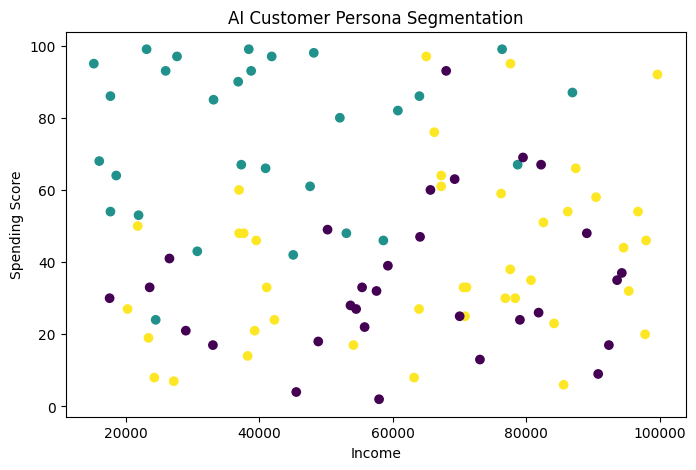

In [5]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["Income"],
    df["Spending_Score"],
    c=df["Customer_Segment"]
)

plt.xlabel("Income")
plt.ylabel("Spending Score")
plt.title("AI Customer Persona Segmentation")

plt.show()